# Synthetic parameter recovery: homogeneous phantom and BrainWeb anatomy

**Can diffusion and proliferation be recovered from noisy, blurred,
low-resolution observations?** Choose **Run All** from the repository root.

- **Part A** retains the homogeneous 3D two-rate experiment used in the manuscript.
- **Part B** estimates independent white-matter diffusion, gray-matter diffusion
  and shared proliferation on the full BrainWeb anatomy. It adds bootstrap
  uncertainty, withheld forecasts, repeated-noise validation and an anatomy/grid
  stress test. Search for “Part B” to run that section separately.

Allow about **3–5 minutes** for both default experiments after Numba compilation.
The calibrated MRI-like signal is a synthetic cellularity proxy. These controlled
experiments do not establish patient MRI calibration or clinical validity.

# Part A — homogeneous phantom (D, ρ)


## Model and synthetic measurement experiment

Write $u=c/K$ for normalized viable cell density. With known, constant carrying
capacity $K$, homogeneous diffusion $D$ and proliferation $\rho$,

$$\partial_t u=D\nabla^2u+\rho u(1-u),\qquad
\nabla u\cdot\mathbf n=0\quad\text{on the box boundary}.$$

The initial condition is a fixed Gaussian with peak 0.2 and widths (5, 4, 5) mm,
centered at (−3, 2, 0) mm. Its finite-volume cell averages are integrated
analytically. It is smooth and untruncated, unlike the compact seed option in the
explorer. We reuse the explorer's conservative no-flux diffusion and exact
logistic-reaction kernel (`brainweb_kpp.model.advance`) with float64 arithmetic.
This experiment estimates a **single tissue migration coefficient**, not separate
white/gray matter coefficients and not the water ADC measured by diffusion MRI.

At each scan time $t_j$, the imaging operator $H$ applies a Gaussian point-spread
function (2 mm standard deviation), then averages disjoint 6 mm cubic voxels:

$$y_{jv}=H[u(D_*,\rho_*,t_j)]_v+\epsilon_{jv},\qquad
\epsilon_{jv}\overset{\mathrm{iid}}\sim\mathcal N(0,\sigma^2),\quad \sigma=0.03.$$

Noise is added **after** imaging, so the likelihood's independent-noise assumption
matches the experiment. Noisy values can lie outside [0,1] and are never clipped
for fitting. Only image color scales are limited. This Gaussian signal is a
cellularity proxy; it is not raw MRI magnitude data, which require a different
observation/noise model.

Scans at days **20, 40, 60** are used for fitting. Days **75, 90** are withheld.
The initial state, time origin, $K$, signal scale, point-spread function and noise
level are known. Uncertainty below is conditional on these strong assumptions.

In [1]:
from dataclasses import asdict, replace
from pathlib import Path
import hashlib
import json
import nbformat
import platform
import time

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np
import scipy
from scipy.stats import binomtest, chi2
from numba import set_num_threads
from IPython.display import Markdown, display

from brainweb_kpp.inference import Phantom, SyntheticExperiment, fit_parameters

# Small repeated solves are faster with one Numba thread.
set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
ROOT = Path.cwd()
assert (ROOT / "pyproject.toml").exists(), "Start Jupyter in the repository root."
OUTPUT = ROOT / "outputs" / "synthetic_recovery"
OUTPUT.mkdir(parents=True, exist_ok=True)

SEED = 20261017
TRUE_PARAMETERS = np.array([0.300, 0.045])  # mm²/day, day⁻¹
SCAN_DAYS = np.array([20., 40., 60., 75., 90.])
N_TRAIN = 3
NOISE_SD = 0.03
BOUNDS = ((0.05, 0.01), (0.8, 0.09))  # optimizer constraints, not probability priors
N_BOOTSTRAP = 100
N_COVERAGE = 60  # increase to >= 500 for a more precise coverage assessment

phantom = Phantom()
inverse = SyntheticExperiment(phantom)  # dx = 2 mm, maximum dt = 0.25 day
truth = SyntheticExperiment(replace(phantom, dx_mm=1.0, dt_days=0.0625))
train_days, test_days = SCAN_DAYS[:N_TRAIN], SCAN_DAYS[N_TRAIN:]
noise_rng, bootstrap_rng, coverage_rng, forecast_rng = [
    np.random.default_rng(s) for s in np.random.SeedSequence(SEED).spawn(4)
]

def show_table(headers, rows):
    display(Markdown("| " + " | ".join(headers) + " |\n| " +
                     " | ".join(["---"] * len(headers)) + " |\n" +
                     "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)))

def save_figure(name):
    plt.savefig(OUTPUT / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()

started = time.perf_counter()
print(f"Python {platform.python_version()}, NumPy {np.__version__}, SciPy {scipy.__version__}")
print(f"Training scans: {train_days}; withheld: {test_days}; seed: {SEED}")

Python 3.12.2, NumPy 2.5.4, SciPy 1.18.1
Training scans: [20. 40. 60.]; withheld: [75. 90.]; seed: 20261017


## Generate data independently of the inversion discretization

The generating simulation uses **1 mm / 0.0625 day** resolution; inversion uses
**2 mm / 0.25 day**. Both are stable over the allowed parameter range and use the
same PDE and numerical family. This avoids using identical discrete simulations
for truth and fitting, but remains a correctly specified synthetic biology and
imaging model. Shared structural assumptions make this substantially easier than
patient inference. We explicitly measure discretization discrepancy below.

Observation shape: (5, 10, 10, 10); 3,000 training measurements
Unclipped signal range: -0.099 to 0.572


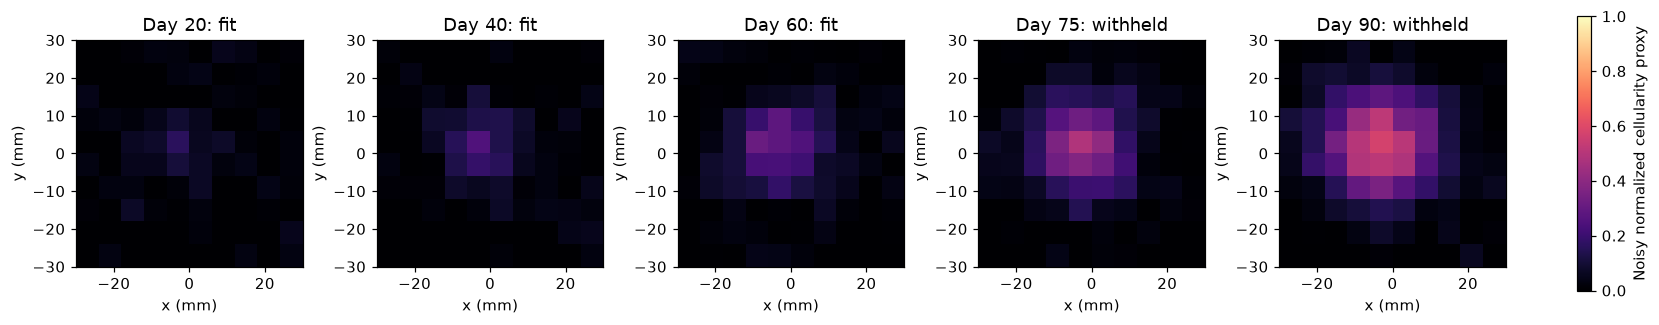

In [2]:
clean = truth.predict(*TRUE_PARAMETERS, SCAN_DAYS)
observed = clean + NOISE_SD * noise_rng.standard_normal(clean.shape)
train_observed = observed[:N_TRAIN].copy()
print(f"Observation shape: {observed.shape}; {train_observed.size:,} training measurements")
print(f"Unclipped signal range: {observed.min():.3f} to {observed.max():.3f}")

extent = [-phantom.width_mm / 2, phantom.width_mm / 2] * 2
mid = observed.shape[-1] // 2
fig, axes = plt.subplots(1, len(SCAN_DAYS), figsize=(15, 3.2), layout="constrained")
for j, ax in enumerate(axes):
    image = ax.imshow(observed[j, :, :, mid].T, origin="lower", extent=extent,
                      cmap="magma", vmin=0, vmax=1)
    ax.set(title=f"Day {SCAN_DAYS[j]:g}: {'fit' if j < N_TRAIN else 'withheld'}",
           xlabel="x (mm)", ylabel="y (mm)")
fig.colorbar(image, ax=axes, shrink=0.8, label="Noisy normalized cellularity proxy")
save_figure("observations")

## Estimate positive rates and local confidence intervals

Optimize $\theta=(\log D,\log\rho)$ by bounded Gaussian maximum likelihood:

$$\widehat\theta=\arg\min_\theta\frac12\sum_{j\in\mathrm{train},v}
\left[\frac{H[u(e^{\theta_1},e^{\theta_2},t_j)]_v-y_{jv}}{\sigma}\right]^2.$$

All training voxels are used; there is no truth-based or noisy-threshold ROI
selection. Three starting guesses check convergence. Bounds enforce a broad
positive search region; **no Bayesian prior** is used. The weighted residual
Jacobian $J$ gives the local approximation
$\mathrm{Cov}(\widehat\theta)\approx(J^TJ)^{-1}$. Marginal 95% Wald confidence
intervals are $\exp[\widehat\theta_i\pm1.96\sqrt{\mathrm{Cov}_{ii}}]$.
The noise scale is known, so this covariance is not multiplied by residual
variance. Rank deficiency raises an error; boundary fits are flagged.

These are asymptotic **confidence intervals**, conditional on the measurement
and initialization model. They do not account for unknown noise, registration,
segmentation, initialization, $K$, imaging calibration or structural model error.

In [3]:
starts = [(0.12, 0.02), (0.3, 0.04), (0.65, 0.075)]
fits = [fit_parameters(inverse, train_days, train_observed, NOISE_SD,
                       start=s, bounds=BOUNDS) for s in starts]
fit = min(fits, key=lambda f: np.sum(f.standardized_residuals**2))
if any(f.at_bound for f in fits):
    raise RuntimeError("A fit is at a bound; revisit the bounds before interpreting Wald intervals.")
show_table(["Start (D, ρ)", "Estimated D", "Estimated ρ", "Residual RMS / σ"], [
    [str(s), f"{f.parameters[0]:.6f}", f"{f.parameters[1]:.6f}",
     f"{np.sqrt(np.mean(f.standardized_residuals**2)):.3f}"]
    for s, f in zip(starts, fits)])
show_table(["Parameter", "Known", "Estimate", "Local 95% CI", "Relative error"], [
    [label, f"{true:g}", f"{estimate:.6f}", f"[{ci[0]:.6f}, {ci[1]:.6f}]",
     f"{100*(estimate/true-1):+.2f}%"]
    for label, true, estimate, ci in zip(
        ["D (mm²/day)", "ρ (day⁻¹)"], TRUE_PARAMETERS, fit.parameters, fit.intervals)])
print(f"Log-parameter correlation: {fit.correlation:+.3f}")
print(f"Weighted Jacobian singular values: {fit.singular_values.round(3)}")
print("Finite singular values and multi-start agreement are local diagnostics, not proof of global identifiability.")

| Start (D, ρ) | Estimated D | Estimated ρ | Residual RMS / σ |
| --- | --- | --- | --- |
| (0.12, 0.02) | 0.303262 | 0.045101 | 1.013 |
| (0.3, 0.04) | 0.303262 | 0.045101 | 1.013 |
| (0.65, 0.075) | 0.303262 | 0.045101 | 1.013 |

| Parameter | Known | Estimate | Local 95% CI | Relative error |
| --- | --- | --- | --- | --- |
| D (mm²/day) | 0.3 | 0.303262 | [0.272171, 0.337906] | +1.09% |
| ρ (day⁻¹) | 0.045 | 0.045101 | [0.044132, 0.046091] | +0.22% |

Log-parameter correlation: +0.540
Weighted Jacobian singular values: [107.892  18.011]
Finite singular values and multi-start agreement are local diagnostics, not proof of global identifiability.


## Parametric bootstrap and joint uncertainty

Generate new training observations from the **fitted** imaging model and refit
both parameters. Percentiles of these estimates give marginal bootstrap
confidence intervals. All trials are retained; a failed or boundary fit stops
the notebook rather than being silently dropped. The joint scatter reveals
parameter dependence. The ellipse is the *local joint* 95% approximation
($\chi^2_2$ cutoff), distinct from marginal 95% intervals.

Bootstrap fits: 25/100


Bootstrap fits: 50/100


Bootstrap fits: 75/100


Bootstrap fits: 100/100


| Parameter | Known | Bootstrap 95% CI | Known value inside? |
| --- | --- | --- | --- |
| D (mm²/day) | 0.3 | [0.272571, 0.335068] | True |
| ρ (day⁻¹) | 0.045 | [0.044295, 0.046042] | True |

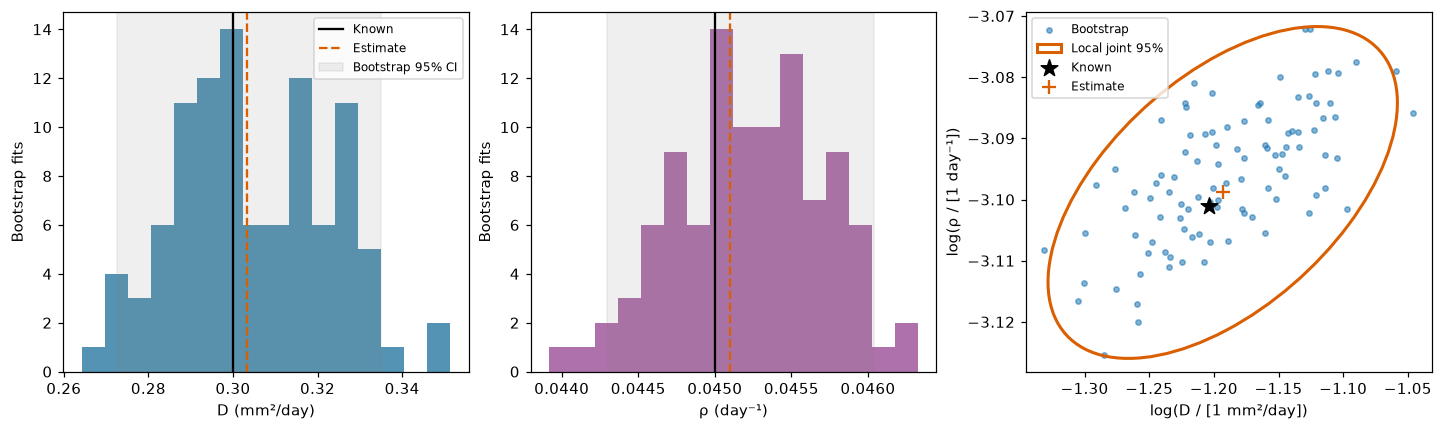

In [4]:
fitted_training = inverse.predict(*fit.parameters, train_days)
bootstrap_parameters = np.empty((N_BOOTSTRAP, 2))
for b in range(N_BOOTSTRAP):
    sample = fitted_training + NOISE_SD * bootstrap_rng.standard_normal(fitted_training.shape)
    boot_fit = fit_parameters(inverse, train_days, sample, NOISE_SD,
                              start=fit.parameters, bounds=BOUNDS)
    if boot_fit.at_bound:
        raise RuntimeError(f"Bootstrap fit {b} reached a bound; intervals need review.")
    bootstrap_parameters[b] = boot_fit.parameters
    if (b + 1) % 25 == 0:
        print(f"Bootstrap fits: {b + 1}/{N_BOOTSTRAP}", flush=True)
bootstrap_ci = np.quantile(bootstrap_parameters, [0.025, 0.975], axis=0).T
show_table(["Parameter", "Known", "Bootstrap 95% CI", "Known value inside?"], [
    [name, f"{value:g}", f"[{ci[0]:.6f}, {ci[1]:.6f}]", str(ci[0] <= value <= ci[1])]
    for name, value, ci in zip(["D (mm²/day)", "ρ (day⁻¹)"], TRUE_PARAMETERS, bootstrap_ci)])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for k, ax in enumerate(axes[:2]):
    ax.hist(bootstrap_parameters[:, k], bins=16, alpha=0.8, color=["#2978a0", "#9b4d96"][k])
    ax.axvline(TRUE_PARAMETERS[k], color="black", label="Known")
    ax.axvline(fit.parameters[k], color="#d95f02", linestyle="--", label="Estimate")
    ax.axvspan(*bootstrap_ci[k], color="gray", alpha=0.12, label="Bootstrap 95% CI")
    ax.set(xlabel=["D (mm²/day)", "ρ (day⁻¹)"][k], ylabel="Bootstrap fits")
axes[0].legend(fontsize=8)
ax = axes[2]
log_boot = np.log(bootstrap_parameters)
ax.scatter(log_boot[:, 0], log_boot[:, 1], s=12, alpha=0.55, label="Bootstrap")
eigenvalues, eigenvectors = np.linalg.eigh(fit.log_covariance)
order = np.argsort(eigenvalues)[::-1]
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))
width, height = 2 * np.sqrt(chi2.ppf(0.95, 2) * eigenvalues)
ax.add_patch(Ellipse(np.log(fit.parameters), width, height, angle=angle,
                     fill=False, edgecolor="#d95f02", linewidth=2, label="Local joint 95%"))
ax.scatter(*np.log(TRUE_PARAMETERS), marker="*", s=130, c="black", label="Known")
ax.scatter(*np.log(fit.parameters), marker="+", s=80, c="#d95f02", label="Estimate")
ax.set(xlabel="log(D / [1 mm²/day])", ylabel="log(ρ / [1 day⁻¹])")
ax.legend(fontsize=8)
save_figure("parameter_uncertainty")

## Forecast withheld scans, with parameter and observation uncertainty

No day-75 or day-90 measurement enters fitting or bootstrap recovery.
Propagate every bootstrap parameter pair through the forward model. Percentile
bands describe approximate pointwise confidence in the **noise-free mean
signal**. Adding independent new measurement noise gives approximate pointwise
**prediction intervals for a new observed scan**. They are wider and have a
different meaning. They are not simultaneous bands over the entire image.

Predictive Monte Carlo resamples the 100 fitted bootstrap trajectories and adds
new noise 1,000 times; this reduces noise-quantile error without additional PDE
solves. Increasing bootstrap fits improves parameter-tail precision.

| Withheld day | RMSE vs clean truth | RMSE vs noisy scan | Voxel fraction in 95% prediction interval |
| --- | --- | --- | --- |
| 75 | 0.00047 | 0.03036 | 94.0% |
| 90 | 0.00084 | 0.03018 | 94.6% |

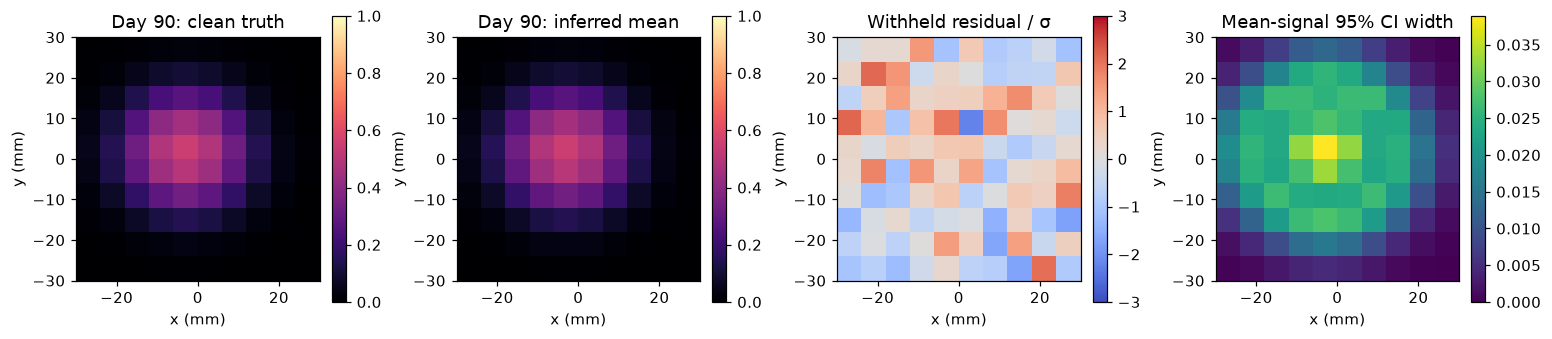

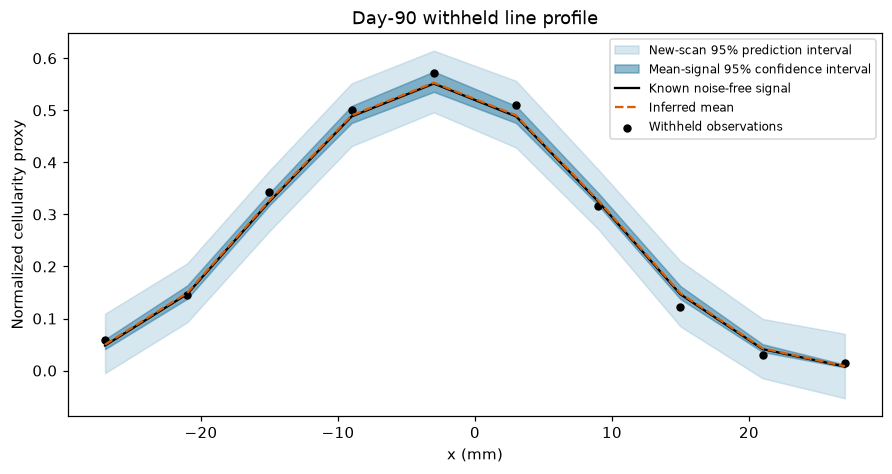

In [5]:
predicted = inverse.predict(*fit.parameters, SCAN_DAYS)
bootstrap_predictions = np.array([inverse.predict(*p, SCAN_DAYS)
                                  for p in bootstrap_parameters])
mean_band = np.quantile(bootstrap_predictions, [0.025, 0.975], axis=0)
replicate_predictions = bootstrap_predictions[
    forecast_rng.integers(N_BOOTSTRAP, size=1000)].copy()
replicate_predictions += NOISE_SD * forecast_rng.standard_normal(replicate_predictions.shape)
prediction_band = np.quantile(replicate_predictions, [0.025, 0.975], axis=0)
del replicate_predictions

clean_rmse = np.sqrt(np.mean((predicted - clean)**2, axis=(1, 2, 3)))
noisy_rmse = np.sqrt(np.mean((predicted - observed)**2, axis=(1, 2, 3)))
predictive_coverage = np.mean((observed >= prediction_band[0]) &
                              (observed <= prediction_band[1]), axis=(1, 2, 3))
show_table(["Withheld day", "RMSE vs clean truth", "RMSE vs noisy scan", "Voxel fraction in 95% prediction interval"], [
    [f"{SCAN_DAYS[j]:g}", f"{clean_rmse[j]:.5f}", f"{noisy_rmse[j]:.5f}",
     f"{predictive_coverage[j]:.1%}"] for j in range(N_TRAIN, len(SCAN_DAYS))])

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), layout="constrained")
fields = [clean[-1], predicted[-1], (observed[-1] - predicted[-1]) / NOISE_SD,
          mean_band[1, -1] - mean_band[0, -1]]
for ax, field, title, cmap, limits in zip(axes, fields,
        ["Day 90: clean truth", "Day 90: inferred mean", "Withheld residual / σ", "Mean-signal 95% CI width"],
        ["magma", "magma", "coolwarm", "viridis"], [(0, 1), (0, 1), (-3, 3), (0, None)]):
    im = ax.imshow(field[:, :, mid].T, origin="lower", extent=extent,
                   cmap=cmap, vmin=limits[0], vmax=limits[1])
    ax.set(title=title, xlabel="x (mm)", ylabel="y (mm)")
    fig.colorbar(im, ax=ax, shrink=0.7)
save_figure("withheld_day90")

coords = (np.arange(observed.shape[1]) + 0.5) * phantom.voxel_mm - phantom.width_mm / 2
ix_y = np.argmin(np.abs(coords - phantom.seed_center_mm[1]))
line = (slice(None), ix_y, mid)
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.fill_between(coords, prediction_band[0, -1][line], prediction_band[1, -1][line],
                color="#8dbbd3", alpha=0.35, label="New-scan 95% prediction interval")
ax.fill_between(coords, mean_band[0, -1][line], mean_band[1, -1][line],
                color="#2978a0", alpha=0.5, label="Mean-signal 95% confidence interval")
ax.plot(coords, clean[-1][line], color="black", label="Known noise-free signal")
ax.plot(coords, predicted[-1][line], "--", color="#d95f02", label="Inferred mean")
ax.scatter(coords, observed[-1][line], c="black", s=20, label="Withheld observations")
ax.set(xlabel="x (mm)", ylabel="Normalized cellularity proxy", title="Day-90 withheld line profile")
ax.legend(fontsize=8)
save_figure("forecast_intervals")

## Independent repeated-noise validation against known parameters

One interval containing the known value is not evidence of 95% coverage.
Generate **60 independent noisy datasets from the fine-grid ground truth**,
fit each using only the early scans, and record bias, RMSE and the fraction of
local 95% intervals covering the true rate. Exact binomial 95% intervals show
how imprecise a small coverage audit is. This audits the **local Jacobian
intervals**; it does not validate bootstrap coverage, which would need a nested
bootstrap or a larger separate study. Trials share biology and initialization
and vary only measurement noise. They are not a virtual patient cohort.

Independent recovery trials: 20/60


Independent recovery trials: 40/60


Independent recovery trials: 60/60


| Parameter | Bias | RMSE | Local 95% CI coverage | 95% binomial CI for coverage |
| --- | --- | --- | --- | --- |
| D (mm²/day) | +0.002637 | 0.017121 | 59/60 (98.3%) | [91.1%, 100.0%] |
| ρ (day⁻¹) | +0.000000 | 0.000448 | 60/60 (100.0%) | [94.0%, 100.0%] |

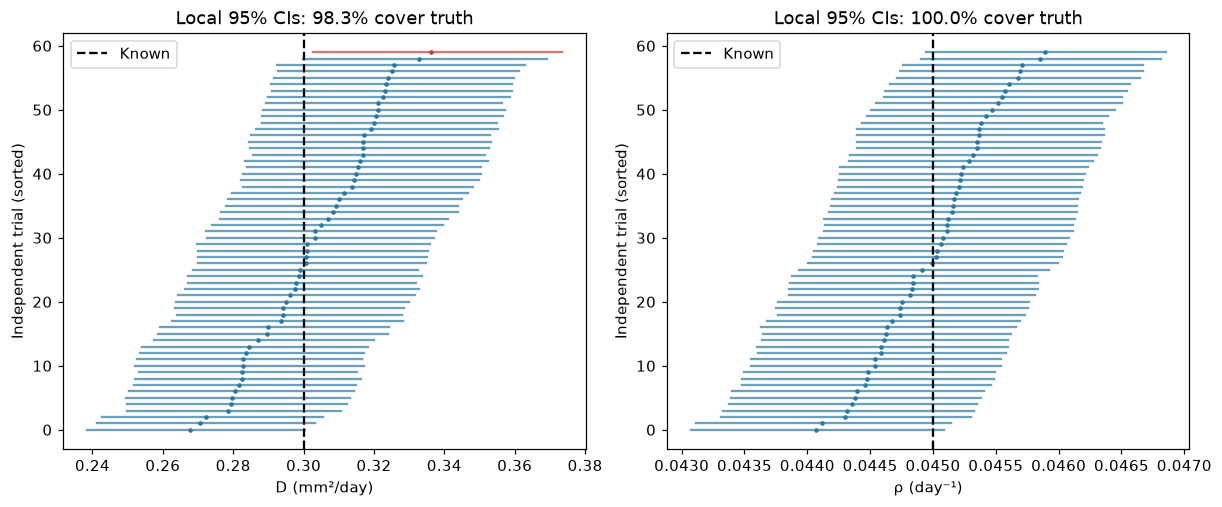

In [6]:
recovered = np.empty((N_COVERAGE, 2))
coverage_intervals = np.empty((N_COVERAGE, 2, 2))
for r in range(N_COVERAGE):
    replicate = clean[:N_TRAIN] + NOISE_SD * coverage_rng.standard_normal(train_observed.shape)
    trial = fit_parameters(inverse, train_days, replicate, NOISE_SD,
                           start=(0.25, 0.04), bounds=BOUNDS)
    if trial.at_bound:
        raise RuntimeError(f"Coverage trial {r} reached a bound; do not discard it.")
    recovered[r], coverage_intervals[r] = trial.parameters, trial.intervals
    if (r + 1) % 20 == 0:
        print(f"Independent recovery trials: {r + 1}/{N_COVERAGE}", flush=True)
contains = ((coverage_intervals[:, :, 0] <= TRUE_PARAMETERS) &
            (coverage_intervals[:, :, 1] >= TRUE_PARAMETERS))
coverage_counts = contains.sum(axis=0)
coverage_fraction = contains.mean(axis=0)
coverage_binomial = np.array([
    tuple(binomtest(int(k), N_COVERAGE).proportion_ci(confidence_level=0.95, method="exact"))
    for k in coverage_counts])
bias = recovered.mean(axis=0) - TRUE_PARAMETERS
parameter_rmse = np.sqrt(np.mean((recovered - TRUE_PARAMETERS)**2, axis=0))
show_table(["Parameter", "Bias", "RMSE", "Local 95% CI coverage", "95% binomial CI for coverage"], [
    [name, f"{bias[k]:+.6f}", f"{parameter_rmse[k]:.6f}",
     f"{coverage_counts[k]}/{N_COVERAGE} ({coverage_fraction[k]:.1%})",
     f"[{coverage_binomial[k, 0]:.1%}, {coverage_binomial[k, 1]:.1%}]"]
    for k, name in enumerate(["D (mm²/day)", "ρ (day⁻¹)"])])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for k, ax in enumerate(axes):
    order = np.argsort(recovered[:, k])
    for row, index in enumerate(order):
        color = "#2978a0" if contains[index, k] else "#c63d32"
        ax.plot(coverage_intervals[index, k], [row, row], color=color, alpha=0.7)
        ax.plot(recovered[index, k], row, ".", color=color, markersize=4)
    ax.axvline(TRUE_PARAMETERS[k], color="black", linestyle="--", label="Known")
    ax.set(xlabel=["D (mm²/day)", "ρ (day⁻¹)"][k], ylabel="Independent trial (sorted)",
           title=f"Local 95% CIs: {coverage_fraction[k]:.1%} cover truth")
    ax.legend()
save_figure("coverage_audit")

## Numerical discrepancy and an identifiability negative control

Compare the inference grid against the finer generator at the known parameters,
and halve the inference time step. Report discrepancies in **observation space**
relative to both the known noise SD and the achieved forecast error. A low
per-voxel discrepancy alone does not guarantee negligible parameter bias when
many voxels are observed; the repeated-noise bias audit above is also needed.

With only a scan at time zero, $D$ and $\rho$ cannot be identified: the initial
state is fixed and its observation does not depend on either rate. The fitter
must reject this experiment rather than manufacture narrow intervals.

In [7]:
coarse_at_truth = inverse.predict(*TRUE_PARAMETERS, SCAN_DAYS)
half_dt = SyntheticExperiment(replace(phantom, dt_days=phantom.dt_days / 2))
half_dt_at_truth = half_dt.predict(*TRUE_PARAMETERS, SCAN_DAYS)
grid_rmse = np.sqrt(np.mean((coarse_at_truth - clean)**2, axis=(1, 2, 3)))
time_rmse = np.sqrt(np.mean((coarse_at_truth - half_dt_at_truth)**2, axis=(1, 2, 3)))
show_table(["Day", "Coarse vs fine RMSE", "RMSE / noise SD", "Halved-dt change RMSE"], [
    [f"{day:g}", f"{g:.6f}", f"{g / NOISE_SD:.3%}", f"{t:.6f}"]
    for day, g, t in zip(SCAN_DAYS, grid_rmse, time_rmse)])

try:
    fit_parameters(inverse, [0.0], inverse.predict(*TRUE_PARAMETERS, [0.0]), NOISE_SD)
except ValueError as error:
    assert "not locally identifiable" in str(error)
    print(f"Expected negative-control result: {error}")
else:
    raise AssertionError("Time-zero data must not identify diffusion or proliferation.")

| Day | Coarse vs fine RMSE | RMSE / noise SD | Halved-dt change RMSE |
| --- | --- | --- | --- |
| 20 | 0.000055 | 0.185% | 0.000006 |
| 40 | 0.000111 | 0.371% | 0.000012 |
| 60 | 0.000185 | 0.617% | 0.000023 |
| 75 | 0.000255 | 0.849% | 0.000039 |
| 90 | 0.000341 | 1.137% | 0.000062 |

Expected negative-control result: D and rho are not locally identifiable in this experiment


## Save reproducible results and interpret the limits

The files in `outputs/synthetic_recovery/` record settings, units, seeds, fitted
values, both interval estimates, independent-trial results, forecast metrics,
input observations and figures. The notebook also retains its executed outputs.
A failed numerical fit is not replaced or excluded from a success-rate report.

**What has been validated?** Recovery of two known parameters and forecasts under
a specified synthetic observation model, with a limited repeated-noise check of
conditional confidence coverage and a numerical-discrepancy check.

**What remains?** Repeat across rates, noise levels, scan schedules, anatomy and
unknown initialization; include spatially correlated noise and imaging-model
mismatch; extend the BrainWeb experiment below across tissue rates and seed locations; compare joint likelihood
profiles with these local intervals; and audit bootstrap coverage with more
replications. Unknown seed age, scale and $K$ can confound inference. A population
prior can regularize a Bayesian model, but sensitivity to that prior must be
reported. Calibrate the observation model with independent MRI/pathology data,
then test blinded later scans and external cohorts before clinical use. Oxygen
and necrosis parameters need additional informative measurements and their own
identifiability analysis.

Useful starting references: [Fisher (1937)](https://doi.org/10.1111/j.1469-1809.1937.tb02153.x),
[Swanson et al. (2000)](https://doi.org/10.1046/j.1365-2184.2000.00177.x),
[glioma-model identifiability (2025)](https://doi.org/10.1098/rsta.2024.0212),
and the SciPy documentation for
[nonlinear least squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html)
and [Gaussian filtering](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.gaussian_filter.html).
See the repository manuscript for broader clinical validation and treatment perspectives.

In [8]:
summary = {
    "experiment": "Homogeneous 3D synthetic Fisher–KPP recovery; calibrated MRI-like proxy",
    "seed": SEED, "rng_streams": ["observations", "bootstrap", "coverage", "prediction"],
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__},
    "parameter_names": ["diffusion", "proliferation"], "parameter_units": ["mm^2/day", "1/day"],
    "inference_phantom": asdict(phantom), "truth_phantom": asdict(truth.phantom),
    "scan_days": SCAN_DAYS.tolist(), "training_indices": list(range(N_TRAIN)),
    "withheld_indices": list(range(N_TRAIN, len(SCAN_DAYS))), "noise_sd": NOISE_SD,
    "optimizer_bounds": BOUNDS, "true_parameters": TRUE_PARAMETERS.tolist(),
    "estimate": fit.parameters.tolist(), "local_95_ci": fit.intervals.tolist(),
    "log_parameter_correlation": float(fit.correlation),
    "log_parameter_covariance": fit.log_covariance.tolist(),
    "bootstrap_replicates": N_BOOTSTRAP, "bootstrap_95_ci": bootstrap_ci.tolist(),
    "coverage_replicates": N_COVERAGE, "coverage_method": "local known-noise Jacobian 95% CI",
    "coverage_counts": coverage_counts.tolist(), "coverage_fraction": coverage_fraction.tolist(),
    "coverage_binomial_95_ci": coverage_binomial.tolist(),
    "repeated_noise_bias": bias.tolist(), "repeated_noise_rmse": parameter_rmse.tolist(),
    "withheld_clean_rmse": clean_rmse[N_TRAIN:].tolist(),
    "withheld_noisy_rmse": noisy_rmse[N_TRAIN:].tolist(),
    "withheld_prediction_interval_voxel_coverage": predictive_coverage[N_TRAIN:].tolist(),
    "coarse_fine_observation_rmse": grid_rmse.tolist(), "halved_dt_observation_rmse": time_rmse.tolist(),
    "limitations": "Known seed/time/K/imaging/noise; Gaussian iid post-imaging noise; no patient validation; conditional pointwise intervals.",
}
np.savez_compressed(OUTPUT / "recovery_data.npz", scan_days=SCAN_DAYS,
                    true_parameters=TRUE_PARAMETERS, clean_observations=clean,
                    noisy_observations=observed, inferred_observations=predicted,
                    bootstrap_parameters=bootstrap_parameters,
                    bootstrap_mean_band=mean_band, prediction_band=prediction_band,
                    independent_recovered_parameters=recovered,
                    independent_local_intervals=coverage_intervals)
source_files = ["src/brainweb_kpp/model.py", "src/brainweb_kpp/inference.py",
                "scripts/run_recovery_notebook.py", "pyproject.toml", "uv.lock"]
summary["source_sha256"] = {
    name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest() for name in source_files
}
notebook = nbformat.read(ROOT / "synthetic_parameter_recovery.ipynb", as_version=4)
notebook_code = "\n\n".join(c.source for c in notebook.cells if c.cell_type == "code"
                           and c.metadata.get("recovery_experiment", "homogeneous") == "homogeneous")
summary["notebook_code_scope"] = "homogeneous"
summary["notebook_code_sha256"] = hashlib.sha256(notebook_code.encode()).hexdigest()
summary["recovery_data_sha256"] = hashlib.sha256((OUTPUT / "recovery_data.npz").read_bytes()).hexdigest()
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print(f"Saved summary, arrays and five figures to outputs/synthetic_recovery/ ({time.perf_counter()-started:.1f} s).")

Saved summary, arrays and five figures to outputs/synthetic_recovery/ (60.9 s).


# Part B — BrainWeb anatomy (D_WM, D_GM, ρ)

This section is self-contained and uses the bundled **original normal BrainWeb
phantom**, not patient tumor images. Run the following cells in order. The T1
volume provides anatomical context; it is **not** the observed tumor signal.
Synthetic tumor observations are generated from known parameters.

On the full parenchymal domain Ω (labels 2, 3 and 8),

$$\partial_t u=\nabla\cdot(D(\mathbf x)\nabla u)+\rho u(1-u),\qquad
\mathbf n\cdot D\nabla u=0\ \text{on}\ \partial\Omega,$$
$$D(\mathbf x)=\begin{cases}D_{\rm WM},&\text{label 3},\\
D_{\rm GM},&\text{labels 2 and 8 (gray/glial)},\end{cases}\qquad u=c/K.$$

CSF and extracerebral tissue have zero cell transport and growth in this
experiment. Diffusive face fluxes use the existing explorer's **harmonic
interface coefficients**. The solver applies conservative explicit diffusion
and exact logistic reaction in float64. There is no mass effect, oxygen,
necrosis, treatment, tensor anisotropy or extra CSF migration parameter here.
The two tissue migration rates are not water ADC values from diffusion MRI.

The known, smooth Gaussian seed is point-sampled on the tissue grid: peak 0.2,
widths (6,6,6) mm, center RAS (−30,25,30) mm. It spans both tissue classes.
The fit estimates **three independent positive rates**; no fixed WM:GM ratio,
ordering constraint or Bayesian prior is imposed. The common proliferation rate
is a deliberate simplification.

In [1]:
from dataclasses import asdict, replace
from pathlib import Path
import hashlib
import json
import nbformat
import platform
import time

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
import numpy as np
import scipy
from scipy.stats import binomtest
from numba import set_num_threads
from IPython.display import Markdown, display

from brainweb_kpp.data import load_brainweb, verify_data
from brainweb_kpp.tissue_inference import (
    BrainWebExperiment, TissueRecoveryDesign, fit_tissue_parameters,
)

set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
bw_root = Path.cwd()
assert (bw_root / "pyproject.toml").exists(), "Start Jupyter in the repository root."
bw_output = bw_root / "outputs" / "brainweb_recovery"
bw_output.mkdir(parents=True, exist_ok=True)
bw_started = time.perf_counter()
bw_manifest = verify_data()

# Editable experiment settings. Keep the physical observation region fixed.
bw_seed = 20261018
bw_true = np.array([.500, .100, .040])  # D_WM, D_GM [mm²/day], rho [day⁻¹]
bw_names = ["D_WM (mm²/day)", "D_GM (mm²/day)", "ρ (day⁻¹)"]
bw_days = np.array([20., 40., 60., 75., 90.])
bw_n_train = 3
bw_noise_sd = .02
bw_bounds = ((.05, .02, .01), (1., .6, .09))  # search bounds, not priors
bw_n_bootstrap = 100
bw_n_coverage = 60  # increase >= 500 for a more precise coverage audit
bw_design = TissueRecoveryDesign()
bw_brain = load_brainweb(3.)
bw_inverse = BrainWebExperiment(bw_brain, bw_design)  # full 3 mm domain, dt <= .5 day
bw_truth = BrainWebExperiment(bw_brain, replace(bw_design, dt_days=.125))
bw_train_days = bw_days[:bw_n_train]
bw_noise_rng, bw_boot_rng, bw_coverage_rng, bw_forecast_rng = [
    np.random.default_rng(s) for s in np.random.SeedSequence(bw_seed).spawn(4)
]

# Prespecified near-seed validation region, independent of the simulated signal.
bw_world_centers = np.stack(np.meshgrid(*bw_inverse.observation_axes, indexing="ij"), axis=-1)
bw_near_seed = np.sum((bw_world_centers - bw_design.seed_center_mm)**2, axis=-1) <= 18.**2

def bw_table(headers, rows):
    display(Markdown("| " + " | ".join(headers) + " |\n| " +
                     " | ".join(["---"] * len(headers)) + " |\n" +
                     "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)))

def bw_save_figure(name):
    plt.savefig(bw_output / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()

print(f"Full BrainWeb grid: {bw_inverse.shape}, {len(bw_inverse.active):,} parenchymal voxels")
print(f"Physical observation grid: {bw_inverse.observation_shape}, {bw_design.voxel_mm:g} mm voxels")
print(f"Training days {bw_train_days}; withheld days {bw_days[bw_n_train:]}; seed {bw_seed}")
bw_initial_mass = bw_inverse.initial.sum()
bw_table(["Tissue", "Domain voxels", "Fraction of initial tumor mass"], [
    [name, int(mask.sum()), f"{bw_inverse.initial[mask].sum()/bw_initial_mass:.1%}"]
    for name, mask in [("WM", bw_brain.labels == 3), ("GM/glial", np.isin(bw_brain.labels, [2, 8]))]])

Full BrainWeb grid: (61, 73, 61), 58,669 parenchymal voxels
Physical observation grid: (10, 10, 10), 6 mm voxels
Training days [20. 40. 60.]; withheld days [75. 90.]; seed 20261018


| Tissue | Domain voxels | Fraction of initial tumor mass |
| --- | --- | --- |
| WM | 25049 | 71.2% |
| GM/glial | 33620 | 28.8% |

## Anatomy and the observation model

The full brain is evolved; only a **fixed 60 mm cube** centered at RAS
(−30,24,30) mm is observed. This is a measurement field of view, not a cropped
PDE boundary. All 1,000 voxels per training scan enter the likelihood, including
low-signal regions. A separate, prespecified 18 mm radius region around the known
seed is used for forecast diagnostics to expose errors hidden by background.

For each scan the operator H blurs u with a 2 mm Gaussian PSF, trilinearly
interpolates the result in physical coordinates and approximates each 6 mm
cube average with 3×3×3 midpoint quadrature. Add iid Gaussian noise **after**
imaging (σ=0.02); do not clip observations for fitting. This known normalized
cellularity proxy is not raw MRI magnitude, an MRI segmentation or an ADC map.

The primary generator uses the **same 3 mm tissue grid** with a finer time step
(0.125 day versus 0.5 day for inversion). This intentionally isolates conditional
recovery with known anatomy. Sharing the PDE, spatial mesh, seed and imaging
operator makes it an easier experiment than patient inference. An additional
2 mm anatomy/grid stress test below measures sensitivity to this shared mesh.

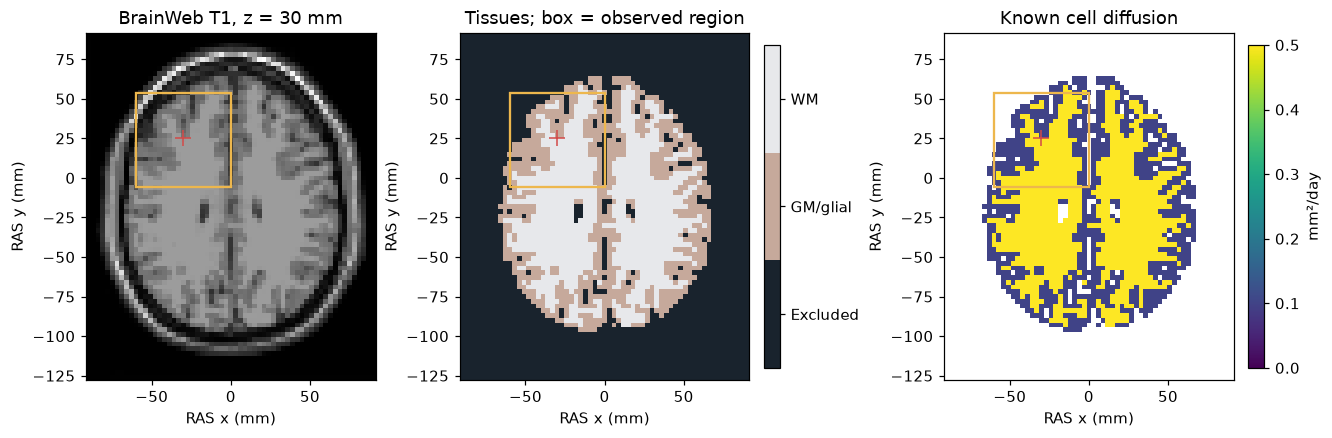

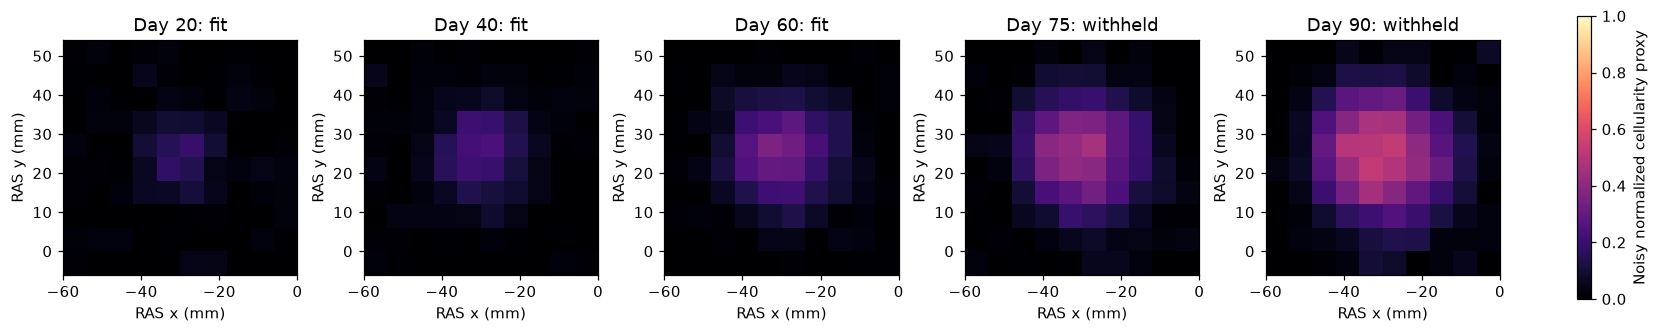

3,000 training measurements; 120 near-seed voxels per scan
Unclipped observed range: -0.0741 to 0.5926


In [2]:
bw_clean = bw_truth.predict(*bw_true, bw_days)
bw_noise = bw_noise_sd * bw_noise_rng.standard_normal(bw_clean.shape)
bw_observed = bw_clean + bw_noise
bw_z = bw_brain.voxel(bw_design.seed_center_mm)[2]
bw_extent = [bw_brain.affine[0, 3] - 1.5,
             bw_brain.affine[0, 3] + (bw_inverse.shape[0] - .5)*3,
             bw_brain.affine[1, 3] - 1.5,
             bw_brain.affine[1, 3] + (bw_inverse.shape[1] - .5)*3]
bw_classes = np.where(bw_brain.labels == 3, 2, np.where(bw_inverse.mask, 1, 0))
bw_dmap = np.where(bw_brain.labels == 3, bw_true[0], np.where(bw_inverse.mask, bw_true[1], np.nan))
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), layout="constrained")
for ax in axes:
    ax.set(xlabel="RAS x (mm)", ylabel="RAS y (mm)")
    ax.add_patch(Rectangle((bw_design.observation_center_mm[0]-30,
                            bw_design.observation_center_mm[1]-30), 60, 60,
                           fill=False, edgecolor="#edb74d", linewidth=1.5))
    ax.plot(*bw_design.seed_center_mm[:2], "+", color="#d34a48", markersize=10)
axes[0].imshow(bw_brain.t1[:, :, bw_z].T, origin="lower", extent=bw_extent, cmap="gray")
axes[0].set_title(f"BrainWeb T1, z = {bw_brain.world((0, 0, bw_z))[2]:g} mm")
im = axes[1].imshow(bw_classes[:, :, bw_z].T, origin="lower", extent=bw_extent,
                     cmap=ListedColormap(["#19232d", "#c6a99b", "#e7e8eb"]), vmin=-.5, vmax=2.5)
cb = fig.colorbar(im, ax=axes[1], ticks=[0, 1, 2], shrink=.65)
cb.ax.set_yticklabels(["Excluded", "GM/glial", "WM"])
axes[1].set_title("Tissues; box = observed region")
im = axes[2].imshow(bw_dmap[:, :, bw_z].T, origin="lower", extent=bw_extent, cmap="viridis", vmin=0, vmax=bw_true[:2].max())
axes[2].set_title("Known cell diffusion")
fig.colorbar(im, ax=axes[2], shrink=.65, label="mm²/day")
bw_save_figure("anatomy_and_design")

bw_obs_extent = [bw_inverse.observation_axes[0][0]-3, bw_inverse.observation_axes[0][-1]+3,
                 bw_inverse.observation_axes[1][0]-3, bw_inverse.observation_axes[1][-1]+3]
bw_mid = int(np.argmin(abs(bw_inverse.observation_axes[2] - bw_design.seed_center_mm[2])))
fig, axes = plt.subplots(1, len(bw_days), figsize=(15, 3.3), layout="constrained")
for j, ax in enumerate(axes):
    im = ax.imshow(bw_observed[j, :, :, bw_mid].T, origin="lower", extent=bw_obs_extent,
                   cmap="magma", vmin=0, vmax=1)
    ax.set(title=f"Day {bw_days[j]:g}: {'fit' if j < bw_n_train else 'withheld'}", xlabel="RAS x (mm)", ylabel="RAS y (mm)")
fig.colorbar(im, ax=axes, shrink=.8, label="Noisy normalized cellularity proxy")
bw_save_figure("observations")
print(f"{bw_observed[:bw_n_train].size:,} training measurements; {bw_near_seed.sum()} near-seed voxels per scan")
print(f"Unclipped observed range: {bw_observed.min():.4f} to {bw_observed.max():.4f}")

## Fit three positive rates and inspect identifiability

Minimize the known-noise Gaussian negative log likelihood in
θ=(log D_WM, log D_GM, log ρ), using days 20/40/60 only:

$$\widehat\theta=\arg\min_\theta\frac12\sum_{j\in\mathrm{train},v}
[(H[u(e^\theta,t_j)]_v-y_{jv})/\sigma]^2.$$

Three starts check optimizer agreement. The weighted residual Jacobian J gives
local covariance (JᵀJ)⁻¹ in log rates and marginal 95% Wald confidence intervals.
Known σ means no residual-variance rescaling. Singular values and correlations
show local sensitivity and trade-offs; they do not prove global identifiability.
A rank-deficient fit raises an error, and a boundary fit stops this analysis.
The bounds restrict a search region and are not probability priors.

In [3]:
bw_starts = [(.25, .20, .025), (.45, .12, .04), (.80, .05, .065)]
bw_fits = [fit_tissue_parameters(bw_inverse, bw_train_days, bw_observed[:bw_n_train],
                                bw_noise_sd, start=s, bounds=bw_bounds) for s in bw_starts]
bw_fit = min(bw_fits, key=lambda f: np.sum(f.standardized_residuals**2))
if any(f.at_bound for f in bw_fits):
    raise RuntimeError("Boundary fit: revisit the experimental design and bounds before interpreting intervals.")
bw_table(["Start (D_WM, D_GM, ρ)", "Estimate", "Residual RMS / σ"], [
    [str(s), str(np.round(f.parameters, 6)), f"{np.sqrt(np.mean(f.standardized_residuals**2)):.3f}"]
    for s, f in zip(bw_starts, bw_fits)])
bw_table(["Parameter", "Known", "Estimate", "Local 95% CI", "Relative error"], [
    [name, f"{value:g}", f"{estimate:.6f}", f"[{ci[0]:.6f}, {ci[1]:.6f}]", f"{100*(estimate/value-1):+.2f}%"]
    for name, value, estimate, ci in zip(bw_names, bw_true, bw_fit.parameters, bw_fit.intervals)])
bw_table(["Log-rate correlation", "D_WM", "D_GM", "ρ"], [
    [name, *[f"{v:+.3f}" for v in row]] for name, row in zip(bw_names, bw_fit.correlation)])
print(f"Weighted Jacobian singular values: {bw_fit.singular_values.round(3)}")
print(f"Jacobian condition number: {bw_fit.singular_values[0]/bw_fit.singular_values[-1]:.2f}")

| Start (D_WM, D_GM, ρ) | Estimate | Residual RMS / σ |
| --- | --- | --- |
| (0.25, 0.2, 0.025) | [0.498062 0.082645 0.039479] | 0.989 |
| (0.45, 0.12, 0.04) | [0.498063 0.082643 0.039479] | 0.989 |
| (0.8, 0.05, 0.065) | [0.498064 0.082642 0.039479] | 0.989 |

| Parameter | Known | Estimate | Local 95% CI | Relative error |
| --- | --- | --- | --- | --- |
| D_WM (mm²/day) | 0.5 | 0.498063 | [0.451209, 0.549782] | -0.39% |
| D_GM (mm²/day) | 0.1 | 0.082643 | [0.057144, 0.119522] | -17.36% |
| ρ (day⁻¹) | 0.04 | 0.039479 | [0.038995, 0.039968] | -1.30% |

| Log-rate correlation | D_WM | D_GM | ρ |
| --- | --- | --- | --- |
| D_WM (mm²/day) | +1.000 | -0.582 | +0.313 |
| D_GM (mm²/day) | -0.582 | +1.000 | +0.137 |
| ρ (day⁻¹) | +0.313 | +0.137 | +1.000 |

Weighted Jacobian singular values: [184.354  24.642   5.246]
Jacobian condition number: 35.14


## Parametric bootstrap uncertainty

Generate 100 independent noisy training datasets from the fitted three-rate
model and refit all three rates. The 2.5th and 97.5th percentiles give marginal
bootstrap confidence intervals. No fits are discarded or replaced. The pair
plots show dependence between rates; gray-matter diffusion can be less precisely
estimated even when proliferation is well constrained. These are conditional
frequentist intervals, not Bayesian credible intervals. One interval containing
the truth is a recovery check, not a coverage validation.

BrainWeb bootstrap fits: 25/100


BrainWeb bootstrap fits: 50/100


BrainWeb bootstrap fits: 75/100


BrainWeb bootstrap fits: 100/100


| Parameter | Bootstrap 95% CI | Known value inside? |
| --- | --- | --- |
| D_WM (mm²/day) | [0.450332, 0.548917] | True |
| D_GM (mm²/day) | [0.055430, 0.107485] | True |
| ρ (day⁻¹) | [0.038857, 0.039920] | False |

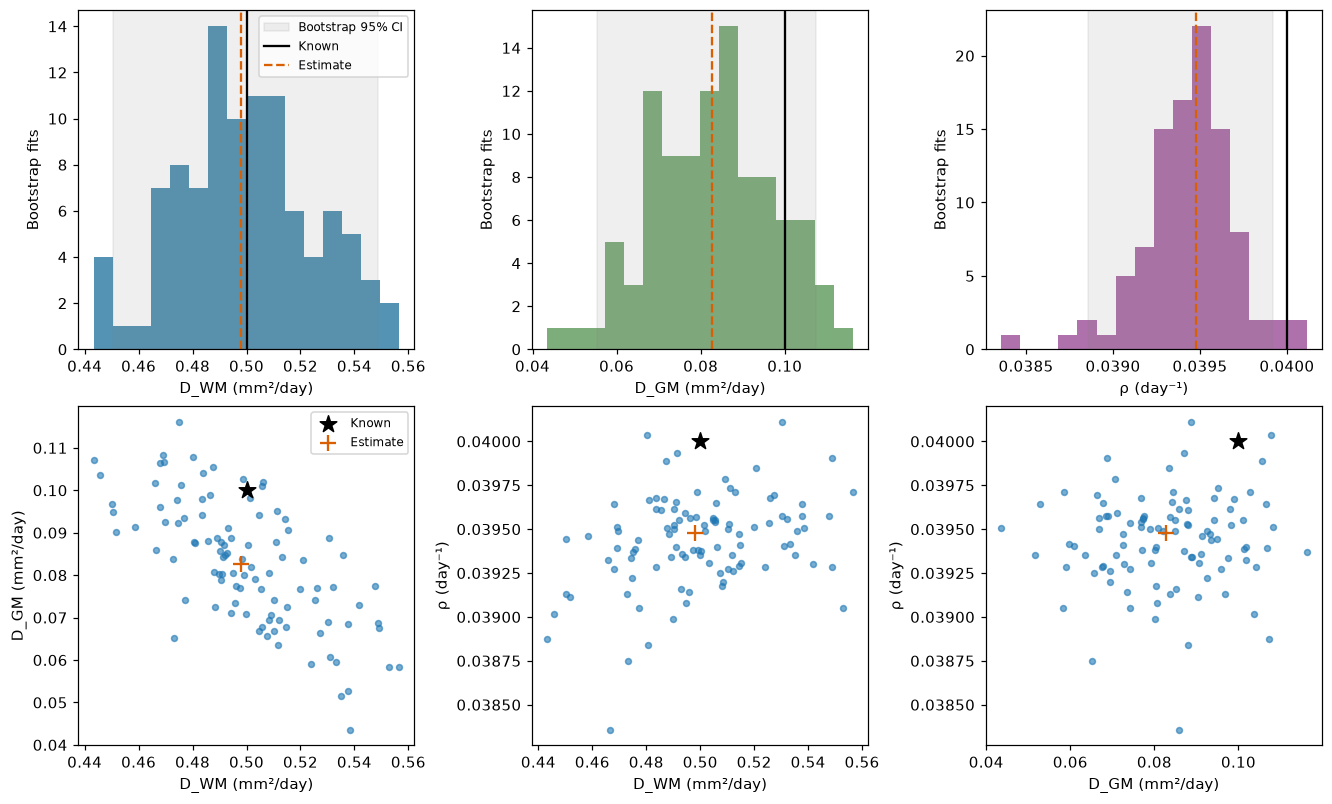

In [4]:
bw_fitted_training = bw_inverse.predict(*bw_fit.parameters, bw_train_days)
bw_bootstrap_parameters = np.empty((bw_n_bootstrap, 3))
for b in range(bw_n_bootstrap):
    sample = bw_fitted_training + bw_noise_sd * bw_boot_rng.standard_normal(bw_fitted_training.shape)
    trial = fit_tissue_parameters(bw_inverse, bw_train_days, sample, bw_noise_sd,
                                 start=bw_fit.parameters, bounds=bw_bounds)
    if trial.at_bound:
        raise RuntimeError(f"Bootstrap {b} reached a bound; do not discard this trial.")
    bw_bootstrap_parameters[b] = trial.parameters
    if (b + 1) % 25 == 0:
        print(f"BrainWeb bootstrap fits: {b+1}/{bw_n_bootstrap}", flush=True)
bw_bootstrap_ci = np.quantile(bw_bootstrap_parameters, [.025, .975], axis=0).T
bw_table(["Parameter", "Bootstrap 95% CI", "Known value inside?"], [
    [name, f"[{ci[0]:.6f}, {ci[1]:.6f}]", str(ci[0] <= value <= ci[1])]
    for name, value, ci in zip(bw_names, bw_true, bw_bootstrap_ci)])

fig, axes = plt.subplots(2, 3, figsize=(12, 7.2), layout="constrained")
for k, ax in enumerate(axes[0]):
    ax.hist(bw_bootstrap_parameters[:, k], bins=16, color=["#2978a0", "#5e995b", "#9b4d96"][k], alpha=.8)
    ax.axvspan(*bw_bootstrap_ci[k], color="gray", alpha=.12, label="Bootstrap 95% CI")
    ax.axvline(bw_true[k], color="black", label="Known")
    ax.axvline(bw_fit.parameters[k], color="#d95f02", linestyle="--", label="Estimate")
    ax.set(xlabel=bw_names[k], ylabel="Bootstrap fits")
axes[0, 0].legend(fontsize=8)
for ax, (a, b) in zip(axes[1], [(0, 1), (0, 2), (1, 2)]):
    ax.scatter(bw_bootstrap_parameters[:, a], bw_bootstrap_parameters[:, b], s=15, alpha=.6)
    ax.scatter(bw_true[a], bw_true[b], marker="*", s=130, color="black", label="Known")
    ax.scatter(bw_fit.parameters[a], bw_fit.parameters[b], marker="+", s=100, color="#d95f02", label="Estimate")
    ax.set(xlabel=bw_names[a], ylabel=bw_names[b])
axes[1, 0].legend(fontsize=8)
bw_save_figure("parameter_uncertainty")

## Withheld forecasts and uncertainty in observations

Days 75 and 90 remain outside fitting and bootstrap estimation. Propagate each
bootstrap triple forward. Pointwise percentiles describe uncertainty in the
noise-free **mean signal**. Adding new independent noise gives wider pointwise
**prediction intervals for a new observed scan**. Resample the 100 trajectories
1,000 times for this noise calculation; this does not add independent parameter
fits. Neither band is simultaneous over the image.

Report metrics for the whole fixed field of view and for the prespecified
near-seed region. Spatial voxel fractions for one scan are descriptive and are
not independent validation of nominal interval coverage.

| Withheld day | Region | RMSE vs clean | RMSE vs noisy | Voxel fraction in 95% prediction interval |
| --- | --- | --- | --- | --- |
| 75 | whole_FOV | 0.00227 | 0.02004 | 94.9% |
| 75 | near_seed_18mm | 0.00496 | 0.02056 | 95.0% |
| 90 | whole_FOV | 0.00372 | 0.02064 | 94.2% |
| 90 | near_seed_18mm | 0.00730 | 0.02344 | 89.2% |

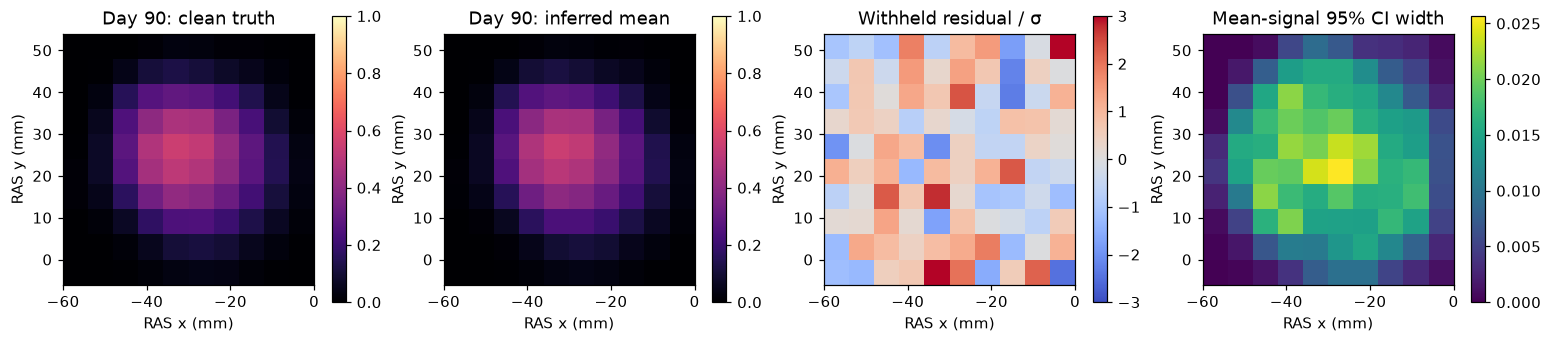

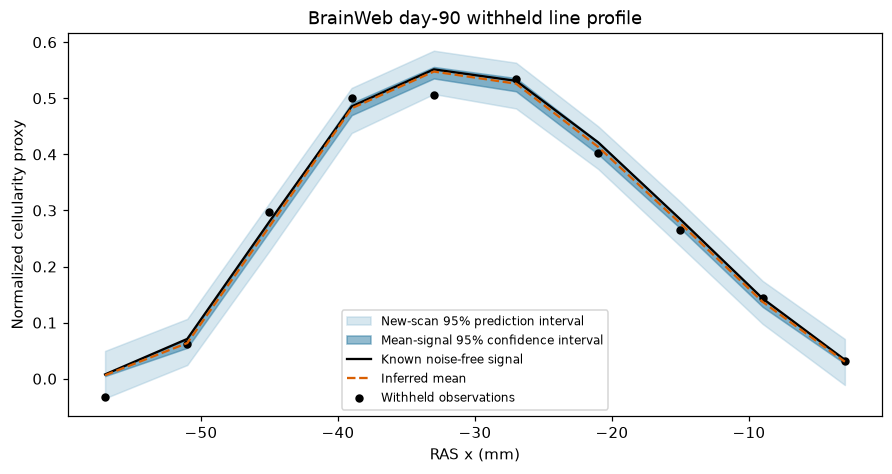

In [5]:
bw_predicted = bw_inverse.predict(*bw_fit.parameters, bw_days)
bw_bootstrap_predictions = np.array([bw_inverse.predict(*p, bw_days) for p in bw_bootstrap_parameters])
bw_mean_band = np.quantile(bw_bootstrap_predictions, [.025, .975], axis=0)
bw_replicate_predictions = bw_bootstrap_predictions[bw_forecast_rng.integers(bw_n_bootstrap, size=1000)].copy()
bw_replicate_predictions += bw_noise_sd * bw_forecast_rng.standard_normal(bw_replicate_predictions.shape)
bw_prediction_band = np.quantile(bw_replicate_predictions, [.025, .975], axis=0)
del bw_replicate_predictions
bw_metrics = {}
for name, mask in [("whole_FOV", np.ones(bw_near_seed.shape, bool)), ("near_seed_18mm", bw_near_seed)]:
    bw_metrics[name] = {
        "clean_rmse": np.sqrt(np.mean((bw_predicted[:, mask] - bw_clean[:, mask])**2, axis=1)),
        "noisy_rmse": np.sqrt(np.mean((bw_predicted[:, mask] - bw_observed[:, mask])**2, axis=1)),
        "prediction_voxel_fraction": np.mean((bw_observed[:, mask] >= bw_prediction_band[0][:, mask]) &
                                             (bw_observed[:, mask] <= bw_prediction_band[1][:, mask]), axis=1),
    }
bw_table(["Withheld day", "Region", "RMSE vs clean", "RMSE vs noisy", "Voxel fraction in 95% prediction interval"], [
    [f"{bw_days[j]:g}", region, f"{metrics['clean_rmse'][j]:.5f}", f"{metrics['noisy_rmse'][j]:.5f}",
     f"{metrics['prediction_voxel_fraction'][j]:.1%}"]
    for j in range(bw_n_train, len(bw_days)) for region, metrics in bw_metrics.items()])

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), layout="constrained")
for ax, field, title, cmap, limits in zip(axes,
        [bw_clean[-1], bw_predicted[-1], (bw_observed[-1]-bw_predicted[-1])/bw_noise_sd,
         bw_mean_band[1, -1]-bw_mean_band[0, -1]],
        ["Day 90: clean truth", "Day 90: inferred mean", "Withheld residual / σ", "Mean-signal 95% CI width"],
        ["magma", "magma", "coolwarm", "viridis"], [(0, 1), (0, 1), (-3, 3), (0, None)]):
    im = ax.imshow(field[:, :, bw_mid].T, origin="lower", extent=bw_obs_extent,
                   cmap=cmap, vmin=limits[0], vmax=limits[1])
    ax.set(title=title, xlabel="RAS x (mm)", ylabel="RAS y (mm)")
    fig.colorbar(im, ax=ax, shrink=.7)
bw_save_figure("withheld_day90")

bw_y = int(np.argmin(abs(bw_inverse.observation_axes[1]-bw_design.seed_center_mm[1])))
bw_line = (slice(None), bw_y, bw_mid)
bw_coords = bw_inverse.observation_axes[0]
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.fill_between(bw_coords, bw_prediction_band[0, -1][bw_line], bw_prediction_band[1, -1][bw_line],
                color="#8dbbd3", alpha=.35, label="New-scan 95% prediction interval")
ax.fill_between(bw_coords, bw_mean_band[0, -1][bw_line], bw_mean_band[1, -1][bw_line],
                color="#2978a0", alpha=.5, label="Mean-signal 95% confidence interval")
ax.plot(bw_coords, bw_clean[-1][bw_line], color="black", label="Known noise-free signal")
ax.plot(bw_coords, bw_predicted[-1][bw_line], "--", color="#d95f02", label="Inferred mean")
ax.scatter(bw_coords, bw_observed[-1][bw_line], color="black", s=20, label="Withheld observations")
ax.set(xlabel="RAS x (mm)", ylabel="Normalized cellularity proxy", title="BrainWeb day-90 withheld line profile")
ax.legend(fontsize=8)
bw_save_figure("forecast_intervals")

## Validate recovery bias and conditional coverage against known rates

Generate **60 fresh, independent noise realizations** from the fine-time-step
3 mm generator, and refit the three early scans. For each rate, report bias,
RMSE and how many **local Jacobian 95% intervals** contain its known value.
Exact binomial intervals show Monte Carlo uncertainty in these coverage
fractions. No trials are omitted. This does not audit bootstrap coverage; that
requires a nested bootstrap or a separate larger experiment.

All repetitions share anatomy, biology, initialization and measurement settings.
They are repeated-noise experiments, not different patients. Coverage need not
be exactly 95% in 60 trials, and a successful check at one parameter triple does
not establish coverage across all rates or observation schedules.

BrainWeb independent recovery trials: 20/60


BrainWeb independent recovery trials: 40/60


BrainWeb independent recovery trials: 60/60


| Parameter | Bias | RMSE | Local 95% CI coverage | 95% binomial CI |
| --- | --- | --- | --- | --- |
| D_WM (mm²/day) | +0.002213 | 0.024388 | 57/60 (95.0%) | [86.1%, 99.0%] |
| D_GM (mm²/day) | +0.001099 | 0.018611 | 55/60 (91.7%) | [81.6%, 97.2%] |
| ρ (day⁻¹) | -0.000011 | 0.000206 | 59/60 (98.3%) | [91.1%, 100.0%] |

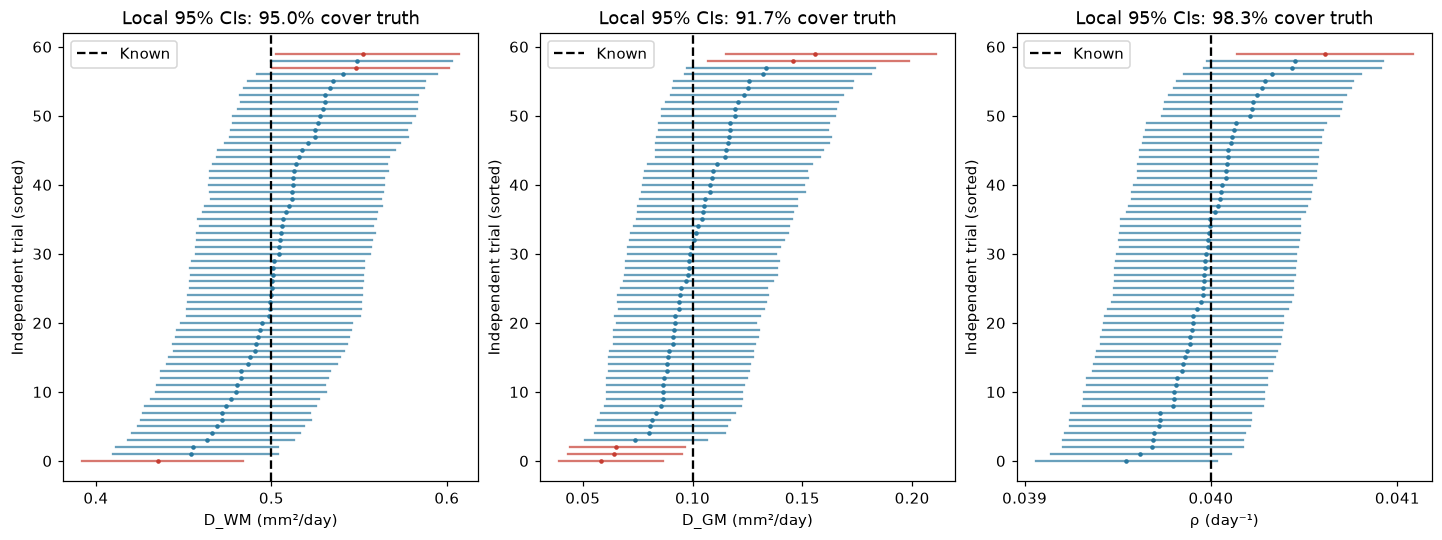

In [6]:
bw_recovered = np.empty((bw_n_coverage, 3))
bw_coverage_intervals = np.empty((bw_n_coverage, 3, 2))
for r in range(bw_n_coverage):
    sample = bw_clean[:bw_n_train] + bw_noise_sd * bw_coverage_rng.standard_normal(bw_fitted_training.shape)
    trial = fit_tissue_parameters(bw_inverse, bw_train_days, sample, bw_noise_sd,
                                 start=(.4, .15, .035), bounds=bw_bounds)
    if trial.at_bound:
        raise RuntimeError(f"Independent trial {r} reached a bound; do not discard it.")
    bw_recovered[r], bw_coverage_intervals[r] = trial.parameters, trial.intervals
    if (r+1) % 20 == 0:
        print(f"BrainWeb independent recovery trials: {r+1}/{bw_n_coverage}", flush=True)
bw_contains = ((bw_coverage_intervals[:, :, 0] <= bw_true) & (bw_coverage_intervals[:, :, 1] >= bw_true))
bw_coverage_counts = bw_contains.sum(axis=0)
bw_coverage_fraction = bw_contains.mean(axis=0)
bw_coverage_binomial = np.array([tuple(binomtest(int(k), bw_n_coverage).proportion_ci(method="exact"))
                                 for k in bw_coverage_counts])
bw_bias = bw_recovered.mean(axis=0)-bw_true
bw_parameter_rmse = np.sqrt(np.mean((bw_recovered-bw_true)**2, axis=0))
bw_table(["Parameter", "Bias", "RMSE", "Local 95% CI coverage", "95% binomial CI"], [
    [name, f"{bw_bias[k]:+.6f}", f"{bw_parameter_rmse[k]:.6f}",
     f"{bw_coverage_counts[k]}/{bw_n_coverage} ({bw_coverage_fraction[k]:.1%})",
     f"[{bw_coverage_binomial[k, 0]:.1%}, {bw_coverage_binomial[k, 1]:.1%}]"]
    for k, name in enumerate(bw_names)])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), layout="constrained")
for k, ax in enumerate(axes):
    for row, index in enumerate(np.argsort(bw_recovered[:, k])):
        color = "#2978a0" if bw_contains[index, k] else "#c63d32"
        ax.plot(bw_coverage_intervals[index, k], [row, row], color=color, alpha=.7)
        ax.plot(bw_recovered[index, k], row, ".", color=color, markersize=4)
    ax.axvline(bw_true[k], color="black", linestyle="--", label="Known")
    ax.set(xlabel=bw_names[k], ylabel="Independent trial (sorted)",
           title=f"Local 95% CIs: {bw_coverage_fraction[k]:.1%} cover truth")
    ax.locator_params(axis="x", nbins=4)
    ax.legend()
bw_save_figure("coverage_audit")

## Temporal error, anatomy/grid mismatch and an identifiability failure

First compare 0.5 day and 0.25 day predictions against the 0.125 day generator
on the **same 3 mm anatomy**. This isolates temporal discretization effects.

Then generate signals on the **full 2 mm BrainWeb grid** at 0.125 day. Physical
observation voxel locations, PSF, quadrature, rates and analytic seed definition
remain fixed. Reuse the primary noise draw for a paired stress comparison.
Refit with the 3 mm inverse model. Also refit the noise-free 2 mm signal to
measure the rate shift induced by anatomy/grid mismatch without noise.
This changes the numerical mesh **and the nearest-neighbor tissue geometry**;
it is not a pure grid-convergence study. Point-sampling the seed and PSF
also changes with resolution. The primary bootstrap does not cover this source
of model discrepancy. Fine-resolution fits would be needed for more demanding
inference.

Finally fit a scan at time zero only. Its signal is independent of all three
rates, so the Jacobian must reject the data as unidentifiable. Unit tests also
reject separate WM/GM inference when the domain contains only one tissue class.

In [7]:
bw_at_truth = bw_inverse.predict(*bw_true, bw_days)
bw_half_dt = BrainWebExperiment(bw_brain, replace(bw_design, dt_days=.25))
bw_half_at_truth = bw_half_dt.predict(*bw_true, bw_days)
bw_temporal_rmse = np.sqrt(np.mean((bw_at_truth-bw_clean)**2, axis=(1, 2, 3)))
bw_half_temporal_rmse = np.sqrt(np.mean((bw_half_at_truth-bw_clean)**2, axis=(1, 2, 3)))

bw_fine_brain = load_brainweb(2.)
bw_fine = BrainWebExperiment(bw_fine_brain, replace(bw_design, dt_days=.125))
bw_fine_clean = bw_fine.predict(*bw_true, bw_days)
bw_grid_rmse = np.sqrt(np.mean((bw_clean-bw_fine_clean)**2, axis=(1, 2, 3)))
bw_stress_observed = bw_fine_clean + bw_noise
bw_stress_fit = fit_tissue_parameters(bw_inverse, bw_train_days, bw_stress_observed[:bw_n_train],
                                     bw_noise_sd, start=(.4, .15, .035), bounds=bw_bounds)
bw_stress_clean_fit = fit_tissue_parameters(bw_inverse, bw_train_days, bw_fine_clean[:bw_n_train],
                                           bw_noise_sd, start=(.4, .15, .035), bounds=bw_bounds)
if bw_stress_fit.at_bound or bw_stress_clean_fit.at_bound:
    raise RuntimeError("The anatomy stress fit reached a bound; inspect model mismatch.")
bw_stress_prediction = bw_inverse.predict(*bw_stress_fit.parameters, bw_days)
bw_stress_forecast_rmse = np.sqrt(np.mean((bw_stress_prediction-bw_fine_clean)**2, axis=(1, 2, 3)))
bw_table(["Day", "dt .5 vs .125 RMSE", "dt .25 vs .125 RMSE", "3 mm vs 2 mm RMSE", "Grid mismatch / σ"], [
    [f"{day:g}", f"{a:.7f}", f"{b:.7f}", f"{c:.7f}", f"{c/bw_noise_sd:.1%}"]
    for day, a, b, c in zip(bw_days, bw_temporal_rmse, bw_half_temporal_rmse, bw_grid_rmse)])
bw_table(["Parameter", "Known", "Primary estimate", "2 mm data: noisy fit", "2 mm data: noiseless fit", "Noiseless relative shift"], [
    [name, f"{value:g}", f"{estimate:.6f}", f"{stress:.6f}", f"{clean_est:.6f}", f"{100*(clean_est/value-1):+.2f}%"]
    for name, value, estimate, stress, clean_est in zip(bw_names, bw_true, bw_fit.parameters,
                                                       bw_stress_fit.parameters, bw_stress_clean_fit.parameters)])
print("Stress-test local 95% intervals are conditional on the misspecified 3 mm model:")
print(bw_stress_fit.intervals)
print("They do not quantify segmentation, anatomy or grid uncertainty.")
try:
    fit_tissue_parameters(bw_inverse, [0.], bw_inverse.predict(*bw_true, [0.]), bw_noise_sd)
except ValueError as error:
    assert "not locally identifiable" in str(error)
    print(f"Expected time-zero negative control: {error}")
else:
    raise AssertionError("Time-zero data must not identify the three rates.")

| Day | dt .5 vs .125 RMSE | dt .25 vs .125 RMSE | 3 mm vs 2 mm RMSE | Grid mismatch / σ |
| --- | --- | --- | --- | --- |
| 20 | 0.0000187 | 0.0000062 | 0.0004182 | 2.1% |
| 40 | 0.0000350 | 0.0000116 | 0.0009008 | 4.5% |
| 60 | 0.0000625 | 0.0000208 | 0.0016979 | 8.5% |
| 75 | 0.0000983 | 0.0000327 | 0.0025639 | 12.8% |
| 90 | 0.0001501 | 0.0000501 | 0.0036814 | 18.4% |

| Parameter | Known | Primary estimate | 2 mm data: noisy fit | 2 mm data: noiseless fit | Noiseless relative shift |
| --- | --- | --- | --- | --- | --- |
| D_WM (mm²/day) | 0.5 | 0.498063 | 0.499160 | 0.500218 | +0.04% |
| D_GM (mm²/day) | 0.1 | 0.082643 | 0.096770 | 0.114350 | +14.35% |
| ρ (day⁻¹) | 0.04 | 0.039479 | 0.039445 | 0.039948 | -0.13% |

Stress-test local 95% intervals are conditional on the misspecified 3 mm model:
[[0.45162176 0.55170211]
 [0.06813386 0.13744123]
 [0.03895939 0.03993756]]
They do not quantify segmentation, anatomy or grid uncertainty.
Expected time-zero negative control: WM diffusion, GM diffusion and proliferation are not locally identifiable


## Save results and interpret the validation

`outputs/brainweb_recovery/` contains a machine-readable summary, observations,
parameter samples, independent-trial intervals, forecast bands and six figures.
Source, experiment-code and data hashes record provenance. The executed notebook
retains all tables and figures; Part A records remain in their original directory.

The validation checks recovery of three known rates under a specified synthetic
measurement model, conditional local coverage, withheld prediction and sensitivity
to discretized anatomy. Narrow intervals depend on known tissue labels, initial
state, elapsed time, capacity, calibrated signal, PSF and noise. The primary
experiment shares the spatial mesh with the generator. Successful recovery here
is **not clinical validation** or evidence that clinical MRI can distinguish
all three rates without calibration.

Next vary seed location, WM/GM contrast, scan schedules and noise. Estimate or
marginalize unknown seed age/shape, tissue labels, signal calibration and noise;
introduce correlated noise and structural mismatch; inspect profile likelihoods
for weakly identified rates. Audit bootstrap coverage separately and increase
replications. MRI/pathology calibration, blinded later scans and independent
patient cohorts are still required. Recovering oxygen and necrosis parameters
requires additional informative observations and a separate identifiability study.

A nominal 95% interval can miss a known value in a single noise realization.
Read the containment table together with the repeated-noise coverage audit;
retain such misses rather than choosing a different seed to make all intervals
contain the truth. A 60-trial audit has substantial binomial uncertainty.

In [8]:
bw_summary = {
    "experiment": "Full BrainWeb synthetic three-rate Fisher-KPP recovery; calibrated cellularity proxy",
    "seed": bw_seed, "rng_streams": ["observations", "bootstrap", "coverage", "prediction"],
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__},
    "parameter_names": ["D_WM", "D_GM", "rho"], "parameter_units": ["mm^2/day", "mm^2/day", "1/day"],
    "design": asdict(bw_design), "truth_design": asdict(bw_truth.design),
    "brainweb_manifest": bw_manifest,
    "inverse_grid": {"spacing_mm": bw_brain.spacing, "shape": list(bw_inverse.shape),
                     "affine": bw_brain.affine.tolist(), "active_voxels": len(bw_inverse.active)},
    "anatomy_stress_grid": {"spacing_mm": bw_fine_brain.spacing, "shape": list(bw_fine.shape),
                            "affine": bw_fine_brain.affine.tolist(), "dt_days": bw_fine.design.dt_days},
    "tissue_rule": "WM label 3; GM/glial labels 2/8; CSF and extracerebral excluded; no-flux interfaces; harmonic faces",
    "observation_rule": "Gaussian PSF then physical trilinear interpolation and 3x3x3 midpoint voxel quadrature; iid noise added after imaging",
    "primary_generator_shares_spatial_mesh": True,
    "scan_days": bw_days.tolist(), "training_indices": list(range(bw_n_train)),
    "withheld_indices": list(range(bw_n_train, len(bw_days))), "noise_sd": bw_noise_sd,
    "near_seed_region_radius_mm": 18., "near_seed_region_voxels": int(bw_near_seed.sum()),
    "optimizer_bounds": bw_bounds, "true_parameters": bw_true.tolist(),
    "estimate": bw_fit.parameters.tolist(), "local_95_ci": bw_fit.intervals.tolist(),
    "weighted_jacobian_singular_values": bw_fit.singular_values.tolist(),
    "log_parameter_correlation": bw_fit.correlation.tolist(), "log_parameter_covariance": bw_fit.log_covariance.tolist(),
    "multistart_estimates": [f.parameters.tolist() for f in bw_fits],
    "bootstrap_replicates": bw_n_bootstrap, "bootstrap_95_ci": bw_bootstrap_ci.tolist(),
    "coverage_replicates": bw_n_coverage, "coverage_method": "local known-noise Jacobian 95% CI; NOT bootstrap coverage",
    "coverage_counts": bw_coverage_counts.tolist(), "coverage_fraction": bw_coverage_fraction.tolist(),
    "coverage_binomial_95_ci": bw_coverage_binomial.tolist(),
    "repeated_noise_bias": bw_bias.tolist(), "repeated_noise_rmse": bw_parameter_rmse.tolist(),
    "forecast_metrics": {region: {k: v.tolist() for k, v in metrics.items()} for region, metrics in bw_metrics.items()},
    "temporal_rmse_dt_0.5_vs_0.125": bw_temporal_rmse.tolist(),
    "temporal_rmse_dt_0.25_vs_0.125": bw_half_temporal_rmse.tolist(),
    "anatomy_grid_observation_rmse_3mm_vs_2mm": bw_grid_rmse.tolist(),
    "anatomy_stress_noisy_estimate": bw_stress_fit.parameters.tolist(),
    "anatomy_stress_noisy_local_95_ci": bw_stress_fit.intervals.tolist(),
    "anatomy_stress_noiseless_estimate": bw_stress_clean_fit.parameters.tolist(),
    "anatomy_stress_forecast_rmse": bw_stress_forecast_rmse.tolist(),
    "boundary_fits": 0, "failed_fits": 0, "time_zero_negative_control": "rank deficiency correctly rejected",
    "limitations": "Known seed/time/K/labels/imaging/noise; same spatial mesh in primary recovery; isotropic tissue rates; iid Gaussian post-imaging noise; conditional pointwise intervals; no patient validation.",
}
np.savez_compressed(bw_output / "recovery_data.npz", scan_days=bw_days,
    true_parameters=bw_true, clean_observations=bw_clean, noisy_observations=bw_observed,
    inferred_observations=bw_predicted, bootstrap_parameters=bw_bootstrap_parameters,
    bootstrap_mean_band=bw_mean_band, prediction_band=bw_prediction_band,
    independent_recovered_parameters=bw_recovered, independent_local_intervals=bw_coverage_intervals,
    observation_centers_ras_mm=bw_world_centers, near_seed_region=bw_near_seed,
    fine_2mm_clean_observations=bw_fine_clean, fine_2mm_noisy_observations=bw_stress_observed,
    anatomy_stress_inferred_observations=bw_stress_prediction,
    coarse_at_truth=bw_at_truth, half_dt_at_truth=bw_half_at_truth)
bw_source_files = ["src/brainweb_kpp/model.py", "src/brainweb_kpp/data.py", "src/brainweb_kpp/tissue_inference.py",
                   "scripts/run_recovery_notebook.py", "pyproject.toml", "uv.lock"]
bw_summary["source_sha256"] = {name: hashlib.sha256((bw_root/name).read_bytes()).hexdigest() for name in bw_source_files}
bw_notebook = nbformat.read(bw_root / "synthetic_parameter_recovery.ipynb", as_version=4)
bw_code = "\n\n".join(c.source for c in bw_notebook.cells if c.cell_type == "code"
                      and c.metadata.get("recovery_experiment") == "brainweb")
bw_summary["notebook_code_scope"] = "brainweb"
bw_summary["notebook_code_sha256"] = hashlib.sha256(bw_code.encode()).hexdigest()
bw_summary["recovery_data_sha256"] = hashlib.sha256((bw_output/"recovery_data.npz").read_bytes()).hexdigest()
(bw_output / "summary.json").write_text(json.dumps(bw_summary, indent=2)+"\n")
print(f"Saved BrainWeb summary, arrays and six figures to outputs/brainweb_recovery/ ({time.perf_counter()-bw_started:.1f} s).")

Saved BrainWeb summary, arrays and six figures to outputs/brainweb_recovery/ (162.9 s).
